# Kontrola skali sygnałów przed normalizacją (gold_dl)
Celem notatnika jest sprawdzenie, w jakim stopniu skala sygnałów elektrofizjologicznych zapisanych w `data/gold_dl` zależy od placówki, w której wykonano badanie, oraz czy niesie informację o zaburzeniach poznawczych (CI) lub wieku pacjenta. Jako miarę skali sygnału przyjęto rozstęp międzykwartylowy `iqr_<kanał>` policzony per pacjent na całym zapisie (kolumny w `patients.parquet`).

Analiza obejmuje kanały EEG, EOG, EMG podbródka, EMG kończyn dolnych i EKG. Pominięto kanały oddechowe (w warstwie silver są już po z-score) oraz SpO2 (wartości bezwzględne). Wszystkie obliczenia wykonano wyłącznie na zbiorze uczącym (`split == "train"`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

In [2]:
PATH = "/home/emil/studia/inzynierka/data/gold_dl/patients.parquet"
df = pd.read_parquet(PATH)
train = df[df["split"] == "train"].reset_index(drop=True)
train.shape

(412, 45)

In [3]:
pd.crosstab(train["SiteID"], train["Cognitive_Impairment"], margins=True)

Cognitive_Impairment,False,True,All
SiteID,,,
I0002,13,12,25
I0006,36,35,71
S0001,157,159,316
All,206,206,412


In [4]:
CHANNELS = [
    "eeg_f3_m2", "eeg_f4_m1", "eeg_c3_m2", "eeg_c4_m1", "eeg_o1_m2", "eeg_o2_m1",
    "eog_e1_m2", "eog_e2_m1",
    "chin_emg_chin1_chin2",
    "leg_emg_lat", "leg_emg_rat",
    "ecg_ecg",
]
SITES = sorted(train["SiteID"].unique())
IQR = [f"iqr_{c}" for c in CHANNELS]

### Braki i zerowe IQR
Brak wartości oznacza kanał nieobecny u pacjenta (`ch_mask_<kanał> == False`). Zerowe IQR oznacza, że co najmniej połowa próbek zapisu ma identyczną wartość. Ponieważ dalsza analiza prowadzona jest na `log(iqr)`, pacjenci z `iqr == 0` są z niej wyłączeni; ich liczba jest raportowana osobno.

In [5]:
braki = pd.DataFrame({
    "n_brak": train[IQR].isna().groupby(train["SiteID"]).sum().stack(),
    "n_zero": (train[IQR] == 0).groupby(train["SiteID"]).sum().stack(),
}).swaplevel().sort_index()
braki.index.names = ["kanal", "SiteID"]
braki[(braki["n_brak"] > 0) | (braki["n_zero"] > 0)]

,,n_brak,n_zero
kanal,SiteID,,
iqr_chin_emg_chin1_chin2,S0001,87,1
iqr_eog_e1_m2,I0002,25,0
iqr_eog_e2_m1,I0002,25,0
iqr_leg_emg_lat,S0001,0,83
iqr_leg_emg_rat,S0001,0,89


In [6]:
long = train.melt(
    id_vars=["patient_id", "SiteID", "Cognitive_Impairment", "Age"],
    value_vars=IQR, var_name="kanal", value_name="iqr",
)
long["kanal"] = long["kanal"].str.removeprefix("iqr_")
long = long[long["iqr"] > 0].copy()
long["log_iqr"] = np.log(long["iqr"])
long.groupby("kanal", sort=False).size().rename("n")

kanal
eeg_f3_m2               412
eeg_f4_m1               412
eeg_c3_m2               412
eeg_c4_m1               412
eeg_o1_m2               412
eeg_o2_m1               412
eog_e1_m2               387
eog_e2_m1               387
chin_emg_chin1_chin2    324
leg_emg_lat             329
leg_emg_rat             323
ecg_ecg                 412
Name: n, dtype: int64

## 1. Skala sygnału w rozbiciu na placówki

### 1.1 Mediana i rozstęp międzykwartylowy `iqr_<kanał>` per placówka
Kolumny `q1`, `mediana`, `q3` opisują rozkład wartości `iqr_<kanał>` wśród pacjentów danej placówki, `iqr_miedzy_pacjentami = q3 - q1`.

In [7]:
def q1(s):
    return s.quantile(0.25)

def q3(s):
    return s.quantile(0.75)

tab_site = (
    long.groupby(["kanal", "SiteID"], sort=False)["iqr"]
    .agg(n="size", q1=q1, mediana="median", q3=q3)
)
tab_site["iqr_miedzy_pacjentami"] = tab_site["q3"] - tab_site["q1"]
tab_site = tab_site.reindex(CHANNELS, level=0)
tab_site.round(3)

n      q1  mediana       q3  \
kanal                SiteID                                  
eeg_f3_m2            I0002    25  13.465   15.551   16.953   
                     I0006    71  14.355   16.375   19.047   
                     S0001   316  13.960   16.018   19.963   
eeg_f4_m1            I0002    25  13.574   15.516   17.898   
                     I0006    71  14.998   16.562   19.414   
                     S0001   316  13.983   16.020   19.992   
eeg_c3_m2            I0002    25  12.211   15.137   16.344   
                     I0006    71  12.328   14.355   17.020   
                     S0001   316  12.054   14.943   18.023   
eeg_c4_m1            I0002    25  12.125   14.477   16.719   
                     I0006    71  12.512   14.906   17.109   
                     S0001   316  12.320   15.072   18.041   
eeg_o1_m2            I0002    25   9.980   11.613   15.371   
                     I0006    71  10.070   12.477   14.906   
                     S0001   316  10.560   13.206   16.817   
eeg_o2_m1            I0002    25  10.648   12.336   14.219   
                     I0006    71   9.930   13.062   14.752   
                     S0001   316  10.807   13.883   17.737   
eog_e1_m2            I0006    71  13.713   16.195   19.875   
                     S0001   316  12.872   15.924   19.062   
eog_e2_m1            I0006    71  15.275   19.289   22.387   
                     S0001   316  13.941   17.004   22.273   
chin_emg_chin1_chin2 I0002    25   2.062    2.824    4.111   
                     I0006    71  22.727   31.562  165.688   
                     S0001   228   3.982    6.026   11.503   
leg_emg_lat          I0002    25   1.243    1.660    1.862   
                     I0006    71   8.234   14.629   20.844   
                     S0001   233   1.998    2.998   21.438   
leg_emg_rat          I0002    25   1.364    1.711    2.230   
                     I0006    71   7.774   12.516   21.754   
                     S0001   227   1.994    2.048   15.193   
ecg_ecg              I0002    25  30.539   52.992   71.258   
                     I0006    71  30.855   43.070   71.141   
                     S0001   316  68.848  106.891  153.062   

                             iqr_miedzy_pacjentami  
kanal                SiteID                         
eeg_f3_m2            I0002                   3.488  
                     I0006                   4.691  
                     S0001                   6.003  
eeg_f4_m1            I0002                   4.324  
                     I0006                   4.416  
                     S0001                   6.009  
eeg_c3_m2            I0002                   4.133  
                     I0006                   4.691  
                     S0001                   5.970  
eeg_c4_m1            I0002                   4.594  
                     I0006                   4.598  
                     S0001                   5.721  
eeg_o1_m2            I0002                   5.391  
                     I0006                   4.836  
                     S0001                   6.258  
eeg_o2_m1            I0002                   3.570  
                     I0006                   4.822  
                     S0001                   6.930  
eog_e1_m2            I0006                   6.162  
                     S0001                   6.190  
eog_e2_m1            I0006                   7.111  
                     S0001                   8.332  
chin_emg_chin1_chin2 I0002                   2.049  
                     I0006                 142.961  
                     S0001                   7.521  
leg_emg_lat          I0002                   0.619  
                     I0006                  12.609  
                     S0001                  19.439  
leg_emg_rat          I0002                   0.866  
                     I0006                  13.979  
                     S0001                  13.200  
ecg_ecg              I0002                  40.71

### 1.2 Iloraz median między placówkami
Iloraz największej i najmniejszej mediany `iqr_<kanał>` spośród placówek, w których kanał jest dostępny.

In [8]:
med_site = tab_site["mediana"].unstack("SiteID").reindex(CHANNELS)
ratio_site = pd.DataFrame({
    "placowka_max": med_site.idxmax(axis=1),
    "placowka_min": med_site.idxmin(axis=1),
    "iloraz_max_min": med_site.max(axis=1) / med_site.min(axis=1),
})
pd.concat([med_site, ratio_site], axis=1).round(3)

,I0002,I0006,S0001,placowka_max,placowka_min,iloraz_max_min
kanal,,,,,,
eeg_f3_m2,15.551,16.375,16.018,I0006,I0002,1.053
eeg_f4_m1,15.516,16.562,16.020,I0006,I0002,1.067
eeg_c3_m2,15.137,14.355,14.943,I0002,I0006,1.054
eeg_c4_m1,14.477,14.906,15.072,S0001,I0002,1.041
eeg_o1_m2,11.613,12.477,13.206,S0001,I0002,1.137
eeg_o2_m1,12.336,13.062,13.883,S0001,I0002,1.125
eog_e1_m2,NaN,16.195,15.924,I0006,S0001,1.017
eog_e2_m1,NaN,19.289,17.004,I0006,S0001,1.134
chin_emg_chin1_chin2,2.824,31.562,6.026,I0006,I0002,11.176


### 1.3 Rozkład `iqr_<kanał>` per placówka

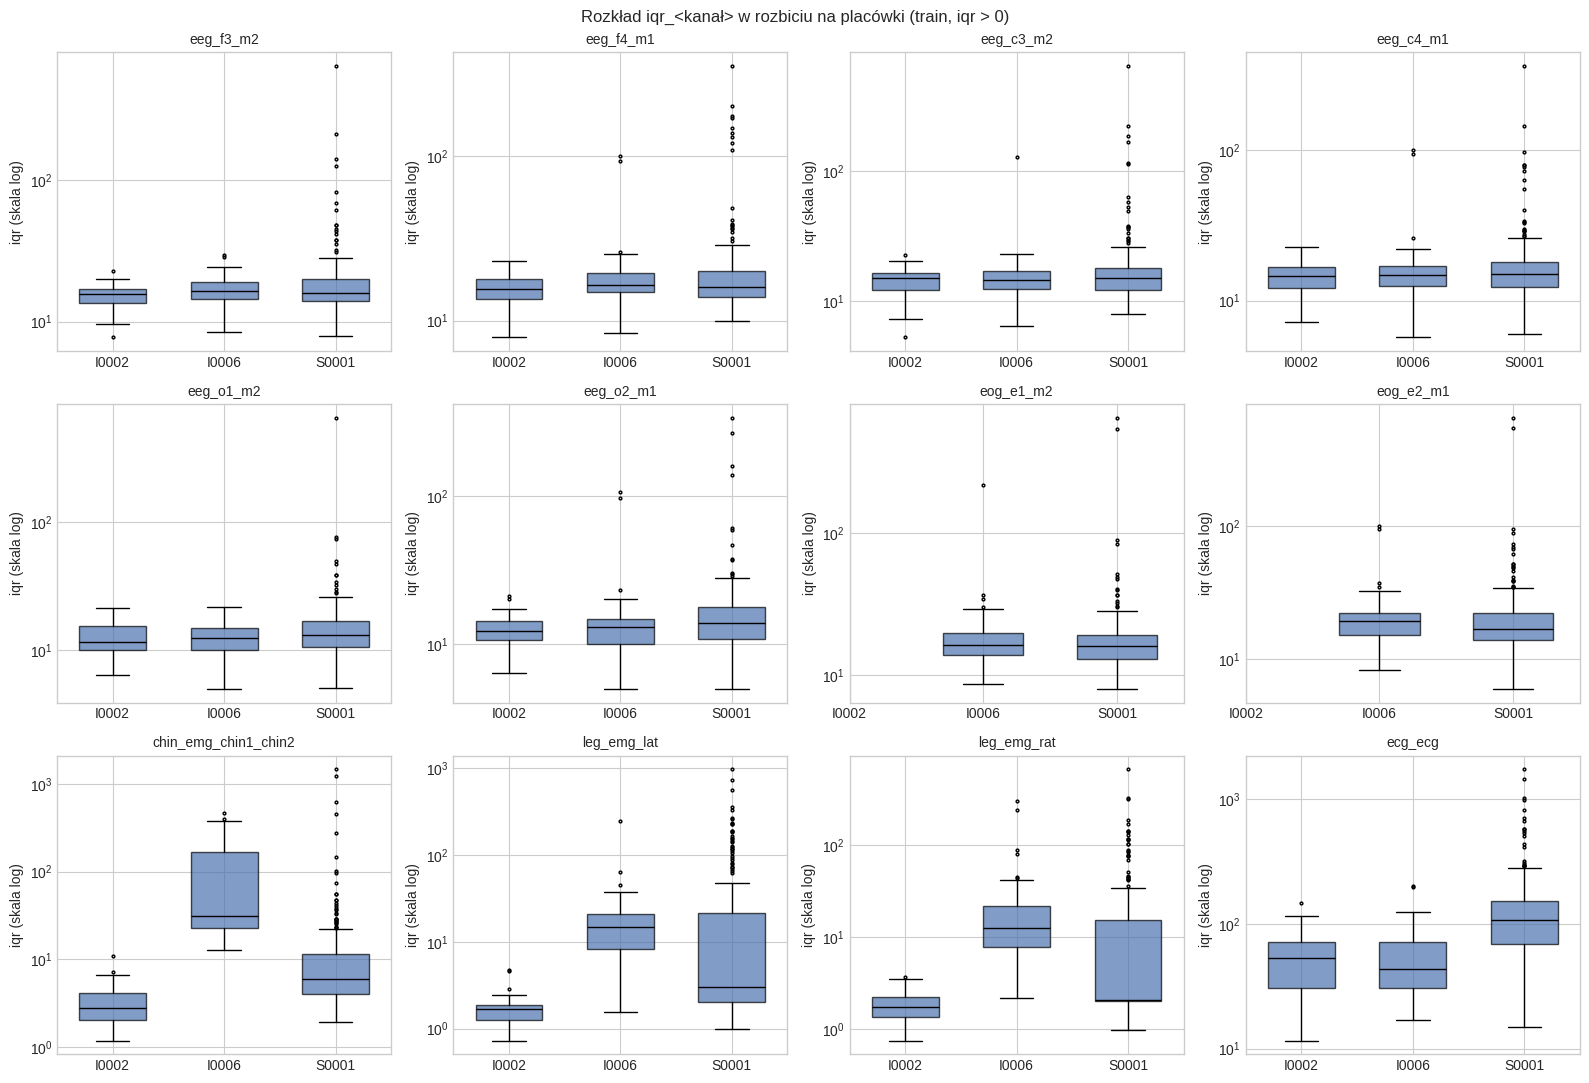

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, c in zip(axes.flat, CHANNELS):
    sub = long[long["kanal"] == c]
    data = [sub.loc[sub["SiteID"] == s, "iqr"] for s in SITES]
    keep = [i for i, d in enumerate(data) if len(d)]
    ax.boxplot([data[i] for i in keep], positions=keep, widths=0.6, patch_artist=True,
               boxprops={"facecolor": "#4C72B0", "alpha": 0.7}, medianprops={"color": "black"},
               flierprops={"markersize": 2})
    ax.set_xticks(range(len(SITES)), SITES)
    ax.set_yscale("log")
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("iqr (skala log)")
fig.suptitle("Rozkład iqr_<kanał> w rozbiciu na placówki (train, iqr > 0)")
fig.tight_layout()
plt.show()

## Wnioski

## 2. Wielkość efektu placówki dla `log(iqr)`
Dla każdego kanału liczone są:
- `eta2` - odsetek wariancji `log(iqr)` wyjaśniony przez SiteID w jednoczynnikowej ANOVA (SS_między / SS_całkowita),
- `F`, `p_anova` - statystyka i p-wartość jednoczynnikowej ANOVA,
- `H`, `p_kw` - test Kruskala-Wallisa,
- `epsilon2` - nieparametryczny odpowiednik eta kwadrat dla testu Kruskala-Wallisa, `H / (n - 1)`.

Dla kanałów EOG placówka I0002 nie ma zapisu, więc porównywane są tylko dwie placówki.

In [10]:
def eta_squared(y, groups):
    y = np.asarray(y, dtype=float)
    groups = np.asarray(groups)
    grand = y.mean()
    ss_total = ((y - grand) ** 2).sum()
    ss_between = sum(
        (groups == g).sum() * (y[groups == g].mean() - grand) ** 2
        for g in np.unique(groups)
    )
    return ss_between / ss_total


def group_effect(data, group_col, value_col="log_iqr"):
    rows = []
    for c in CHANNELS:
        sub = data[data["kanal"] == c]
        samples = [g[value_col].to_numpy() for _, g in sub.groupby(group_col)]
        f, p_f = stats.f_oneway(*samples)
        h, p_h = stats.kruskal(*samples)
        n = len(sub)
        rows.append({
            "kanal": c,
            "n": n,
            "n_grup": len(samples),
            "eta2": eta_squared(sub[value_col], sub[group_col]),
            "F": f,
            "p_anova": p_f,
            "H": h,
            "p_kw": p_h,
            "epsilon2": h / (n - 1),
        })
    return pd.DataFrame(rows).set_index("kanal")

In [11]:
eff_site = group_effect(long, "SiteID")
eff_site.style.format({
    "eta2": "{:.3f}", "F": "{:.1f}", "p_anova": "{:.2e}",
    "H": "{:.1f}", "p_kw": "{:.2e}", "epsilon2": "{:.3f}",
})

,n,n_grup,eta2,F,p_anova,H,p_kw,epsilon2
kanal,,,,,,,,
eeg_f3_m2,412,3,0.007,1.3,2.61e-01,1.9,3.85e-01,0.005
eeg_f4_m1,412,3,0.006,1.3,2.69e-01,3.0,2.20e-01,0.007
eeg_c3_m2,412,3,0.011,2.2,1.12e-01,2.0,3.72e-01,0.005
eeg_c4_m1,412,3,0.008,1.5,2.14e-01,2.0,3.60e-01,0.005
eeg_o1_m2,412,3,0.015,3.0,4.89e-02,4.6,1.01e-01,0.011
eeg_o2_m1,412,3,0.009,1.8,1.69e-01,4.5,1.03e-01,0.011
eog_e1_m2,387,2,0.002,0.8,3.84e-01,1.6,2.01e-01,0.004
eog_e2_m1,387,2,0.003,1.3,2.59e-01,3.3,6.75e-02,0.009
chin_emg_chin1_chin2,324,3,0.399,106.6,3.08e-36,131.4,3.00e-29,0.407


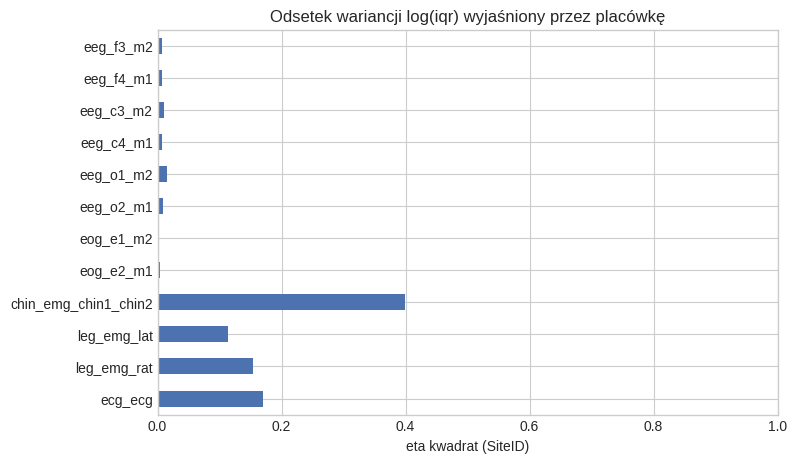

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
eff_site["eta2"].plot.barh(ax=ax, color="#4C72B0")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("eta kwadrat (SiteID)")
ax.set_ylabel("")
ax.set_title("Odsetek wariancji log(iqr) wyjaśniony przez placówkę")
plt.show()

## Wnioski

## 3. Skala sygnału a CI i wiek

### 3.1 `log(iqr)` względem Cognitive_Impairment
Ta sama procedura co w sekcji 2, z grupowaniem po `Cognitive_Impairment`. Dodatkowo podano mediany `iqr` w obu grupach i ich iloraz (CI / bez CI).

In [13]:
med_ci = (
    long.groupby(["kanal", "Cognitive_Impairment"])["iqr"].median()
    .unstack().reindex(CHANNELS)
    .rename(columns={False: "mediana_bez_CI", True: "mediana_CI"})
)
med_ci["iloraz_CI_bez_CI"] = med_ci["mediana_CI"] / med_ci["mediana_bez_CI"]
eff_ci = med_ci.join(group_effect(long, "Cognitive_Impairment"))
eff_ci.style.format({
    "mediana_bez_CI": "{:.3f}", "mediana_CI": "{:.3f}", "iloraz_CI_bez_CI": "{:.3f}",
    "eta2": "{:.4f}", "F": "{:.2f}", "p_anova": "{:.3f}",
    "H": "{:.2f}", "p_kw": "{:.3f}", "epsilon2": "{:.4f}",
})

,mediana_bez_CI,mediana_CI,iloraz_CI_bez_CI,n,n_grup,eta2,F,p_anova,H,p_kw,epsilon2
kanal,,,,,,,,,,,
eeg_f3_m2,15.998,16.096,1.006,412,2,0.0235,9.89,0.002,4.14,0.042,0.0101
eeg_f4_m1,16.010,16.191,1.011,412,2,0.0125,5.19,0.023,3.14,0.076,0.0077
eeg_c3_m2,14.033,15.711,1.120,412,2,0.0135,5.60,0.018,5.72,0.017,0.0139
eeg_c4_m1,14.658,15.820,1.079,412,2,0.0038,1.55,0.214,4.66,0.031,0.0113
eeg_o1_m2,12.045,13.961,1.159,412,2,0.0186,7.78,0.006,8.23,0.004,0.0200
eeg_o2_m1,12.652,13.953,1.103,412,2,0.0124,5.16,0.024,6.43,0.011,0.0157
eog_e1_m2,15.090,16.000,1.060,387,2,0.0075,2.91,0.089,4.57,0.033,0.0118
eog_e2_m1,17.039,18.016,1.057,387,2,0.0092,3.58,0.059,3.53,0.060,0.0092
chin_emg_chin1_chin2,6.027,10.938,1.815,324,2,0.0333,11.08,0.001,10.90,0.001,0.0338


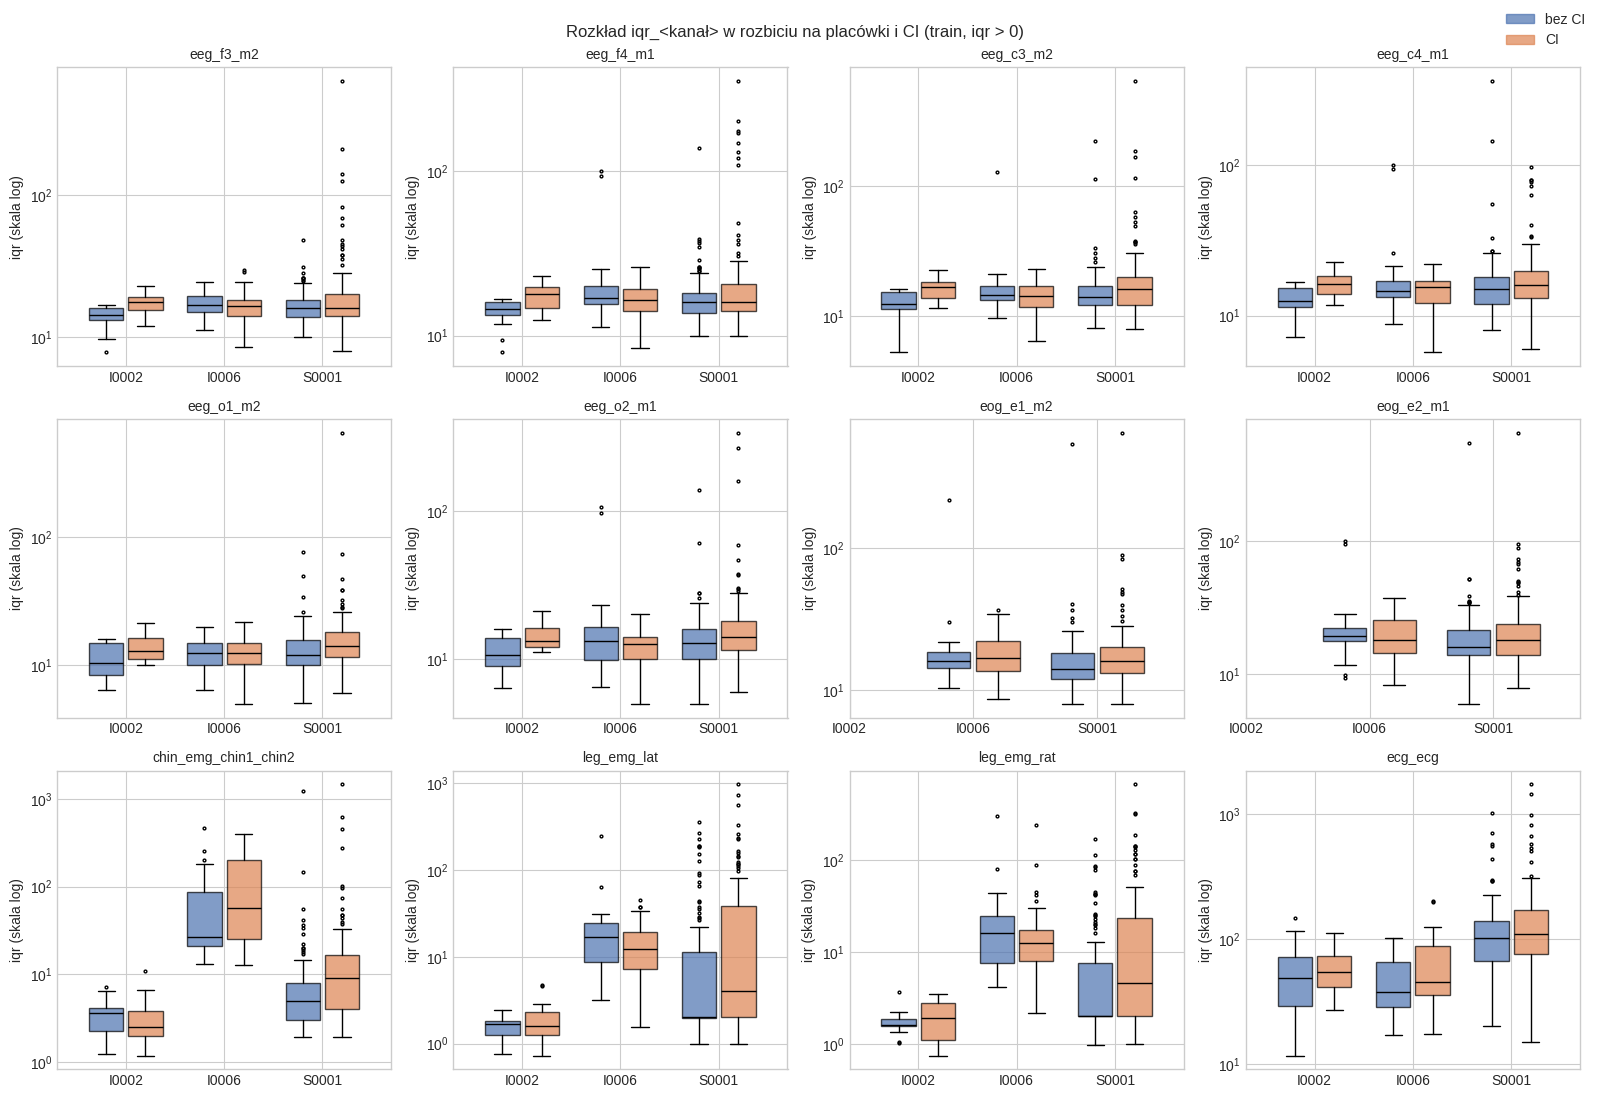

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, c in zip(axes.flat, CHANNELS):
    sub = long[long["kanal"] == c]
    for shift, ci, color in [(-0.2, False, "#4C72B0"), (0.2, True, "#DD8452")]:
        data = [sub.loc[(sub["SiteID"] == s) & (sub["Cognitive_Impairment"] == ci), "iqr"] for s in SITES]
        keep = [i for i, d in enumerate(data) if len(d)]
        ax.boxplot([data[i] for i in keep], positions=[i + shift for i in keep], widths=0.35,
                   patch_artist=True, boxprops={"facecolor": color, "alpha": 0.7},
                   medianprops={"color": "black"}, flierprops={"markersize": 2})
    ax.set_xticks(range(len(SITES)), SITES)
    ax.set_yscale("log")
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("iqr (skala log)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.7) for c in ["#4C72B0", "#DD8452"]]
fig.legend(handles, ["bez CI", "CI"], loc="upper right")
fig.suptitle("Rozkład iqr_<kanał> w rozbiciu na placówki i CI (train, iqr > 0)")
fig.tight_layout()
plt.show()

### 3.2 Korelacja `log(iqr)` z wiekiem
Korelacja rang Spearmana (dla `log(iqr)` równoważna korelacji z `iqr`) oraz korelacja Pearsona dla `log(iqr)`.

In [15]:
def age_corr(data, value_col="log_iqr"):
    rows = []
    for c in CHANNELS:
        sub = data[data["kanal"] == c]
        rho, p_rho = stats.spearmanr(sub["Age"], sub[value_col])
        r, p_r = stats.pearsonr(sub["Age"], sub[value_col])
        rows.append({"kanal": c, "n": len(sub), "spearman_rho": rho, "p_spearman": p_rho,
                     "pearson_r": r, "p_pearson": p_r})
    return pd.DataFrame(rows).set_index("kanal")

corr_age = age_corr(long)
corr_age.style.format({
    "spearman_rho": "{:.3f}", "p_spearman": "{:.3f}",
    "pearson_r": "{:.3f}", "p_pearson": "{:.3f}",
})

,n,spearman_rho,p_spearman,pearson_r,p_pearson
kanal,,,,,
eeg_f3_m2,412,-0.111,0.024,-0.059,0.230
eeg_f4_m1,412,-0.109,0.027,-0.037,0.456
eeg_c3_m2,412,-0.049,0.317,0.042,0.398
eeg_c4_m1,412,-0.076,0.122,-0.031,0.530
eeg_o1_m2,412,-0.025,0.608,0.013,0.790
eeg_o2_m1,412,-0.013,0.789,0.008,0.866
eog_e1_m2,387,-0.067,0.188,0.025,0.629
eog_e2_m1,387,-0.074,0.148,-0.025,0.618
chin_emg_chin1_chin2,324,-0.066,0.236,-0.096,0.086


### 3.3 CI i wiek po usunięciu efektu placówki
Ponieważ placówki różnią się zarówno skalą sygnału, jak i potencjalnie rozkładem wieku, analizę z punktów 3.1 i 3.2 powtórzono na `log(iqr)` scentrowanym w obrębie placówki (odjęta średnia `log(iqr)` danej placówki dla danego kanału).

In [16]:
train.groupby("SiteID")["Age"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
SiteID,,,,,,,,
I0002,25.0,70.8,7.5,56.0,67.0,71.0,75.0,88.0
I0006,71.0,67.5,9.5,50.0,61.0,69.0,74.5,87.0
S0001,316.0,70.6,8.3,50.0,65.0,71.0,77.0,89.0


In [17]:
long["log_iqr_c"] = long["log_iqr"] - long.groupby(["kanal", "SiteID"])["log_iqr"].transform("mean")

eff_ci_c = group_effect(long, "Cognitive_Impairment", "log_iqr_c")[["eta2", "p_anova", "p_kw"]]
corr_age_c = age_corr(long, "log_iqr_c")[["spearman_rho", "p_spearman"]]
within = eff_ci_c.add_suffix("_CI").join(corr_age_c.add_suffix("_wiek"))
within.style.format({
    "eta2_CI": "{:.4f}", "p_anova_CI": "{:.3f}", "p_kw_CI": "{:.3f}",
    "spearman_rho_wiek": "{:.3f}", "p_spearman_wiek": "{:.3f}",
})

,eta2_CI,p_anova_CI,p_kw_CI,spearman_rho_wiek,p_spearman_wiek
kanal,,,,,
eeg_f3_m2,0.0234,0.002,0.051,-0.113,0.022
eeg_f4_m1,0.0124,0.024,0.095,-0.106,0.032
eeg_c3_m2,0.0133,0.019,0.020,-0.060,0.224
eeg_c4_m1,0.0037,0.220,0.035,-0.077,0.120
eeg_o1_m2,0.0185,0.006,0.003,-0.043,0.388
eeg_o2_m1,0.0123,0.025,0.008,-0.019,0.704
eog_e1_m2,0.0076,0.087,0.030,-0.058,0.253
eog_e2_m1,0.0093,0.058,0.052,-0.066,0.192
chin_emg_chin1_chin2,0.0539,0.000,0.000,0.021,0.711


## Wnioski

## Podsumowanie liczbowe
Zestawienie miar z sekcji 1-3. Kategorie wielkości efektu `eta2` wg progów Cohena: < 0.01 pomijalny, 0.01-0.06 mały, 0.06-0.14 średni, >= 0.14 duży.

In [18]:
def eta2_label(v):
    if v < 0.01:
        return "pomijalny"
    if v < 0.06:
        return "maly"
    if v < 0.14:
        return "sredni"
    return "duzy"

summary = pd.DataFrame({
    "iloraz_median_placowek": ratio_site["iloraz_max_min"],
    "eta2_site": eff_site["eta2"],
    "efekt_site": eff_site["eta2"].map(eta2_label),
    "p_kw_site": eff_site["p_kw"],
    "iloraz_CI_bez_CI": eff_ci["iloraz_CI_bez_CI"],
    "eta2_CI": eff_ci["eta2"],
    "p_kw_CI": eff_ci["p_kw"],
    "eta2_CI_w_placowce": within["eta2_CI"],
    "p_kw_CI_w_placowce": within["p_kw_CI"],
    "rho_wiek": corr_age["spearman_rho"],
    "p_wiek": corr_age["p_spearman"],
    "rho_wiek_w_placowce": within["spearman_rho_wiek"],
    "p_wiek_w_placowce": within["p_spearman_wiek"],
})
summary.style.format({
    "iloraz_median_placowek": "{:.2f}", "eta2_site": "{:.3f}", "p_kw_site": "{:.1e}",
    "iloraz_CI_bez_CI": "{:.3f}", "eta2_CI": "{:.4f}", "p_kw_CI": "{:.3f}",
    "eta2_CI_w_placowce": "{:.4f}", "p_kw_CI_w_placowce": "{:.3f}",
    "rho_wiek": "{:.3f}", "p_wiek": "{:.3f}",
    "rho_wiek_w_placowce": "{:.3f}", "p_wiek_w_placowce": "{:.3f}",
})

,iloraz_median_placowek,eta2_site,efekt_site,p_kw_site,iloraz_CI_bez_CI,eta2_CI,p_kw_CI,eta2_CI_w_placowce,p_kw_CI_w_placowce,rho_wiek,p_wiek,rho_wiek_w_placowce,p_wiek_w_placowce
kanal,,,,,,,,,,,,,
eeg_f3_m2,1.05,0.007,pomijalny,3.9e-01,1.006,0.0235,0.042,0.0234,0.051,-0.111,0.024,-0.113,0.022
eeg_f4_m1,1.07,0.006,pomijalny,2.2e-01,1.011,0.0125,0.076,0.0124,0.095,-0.109,0.027,-0.106,0.032
eeg_c3_m2,1.05,0.011,maly,3.7e-01,1.120,0.0135,0.017,0.0133,0.020,-0.049,0.317,-0.060,0.224
eeg_c4_m1,1.04,0.008,pomijalny,3.6e-01,1.079,0.0038,0.031,0.0037,0.035,-0.076,0.122,-0.077,0.120
eeg_o1_m2,1.14,0.015,maly,1.0e-01,1.159,0.0186,0.004,0.0185,0.003,-0.025,0.608,-0.043,0.388
eeg_o2_m1,1.13,0.009,pomijalny,1.0e-01,1.103,0.0124,0.011,0.0123,0.008,-0.013,0.789,-0.019,0.704
eog_e1_m2,1.02,0.002,pomijalny,2.0e-01,1.060,0.0075,0.033,0.0076,0.030,-0.067,0.188,-0.058,0.253
eog_e2_m1,1.13,0.003,pomijalny,6.7e-02,1.057,0.0092,0.060,0.0093,0.052,-0.074,0.148,-0.066,0.192
chin_emg_chin1_chin2,11.18,0.399,duzy,3.0e-29,1.815,0.0333,0.001,0.0539,0.000,-0.066,0.236,0.021,0.711


Efekt placówki dla `log(iqr)` (n pacjentów train z `iqr > 0`):
- **duży** (`eta2 >= 0.14`): `chin_emg_chin1_chin2` (eta2 = 0.399, iloraz median 11.2; I0006 31.6 vs I0002 2.8), `ecg_ecg` (eta2 = 0.170, iloraz 2.5; S0001 106.9 vs I0006 43.1), `leg_emg_rat` (eta2 = 0.154, iloraz 7.3); wszystkie z p_kw < 1e-14,
- **średni**: `leg_emg_lat` (eta2 = 0.114, iloraz 8.8, p_kw < 1e-14),
- **mały**: `eeg_c3_m2` (0.011), `eeg_o1_m2` (0.015); ilorazy median 1.05 i 1.14, p_kw = 0.37 i 0.10,
- **pomijalny** (`eta2 < 0.01`): `eeg_f3_m2`, `eeg_f4_m1`, `eeg_c4_m1`, `eeg_o2_m1`, `eog_e1_m2`, `eog_e2_m1`; ilorazy median 1.02-1.13, p_kw od 0.07 do 0.39.
- Dla EMG kończyn w S0001 83 (`leg_emg_lat`) i 89 (`leg_emg_rat`) z 316 pacjentów ma `iqr == 0`; zostali wyłączeni z analizy `log(iqr)`.

Skala sygnału a CI:
- `eta2` dla CI mieści się w zakresie 0.004-0.033 we wszystkich kanałach (po scentrowaniu w obrębie placówki 0.004-0.054).
- Największe różnice median (CI / bez CI): `leg_emg_rat` 2.91, `leg_emg_lat` 2.29, `chin_emg_chin1_chin2` 1.81 (p_kw = 0.005, 0.009, 0.001); dla EEG i EOG ilorazy 1.01-1.16.
- p_kw < 0.05 dla CI: `eeg_f3_m2`, `eeg_c3_m2`, `eeg_c4_m1`, `eeg_o1_m2`, `eeg_o2_m1`, `eog_e1_m2`, `chin_emg_chin1_chin2`, `leg_emg_lat`, `leg_emg_rat`, `ecg_ecg` (bez korekty na wielokrotne porównania).

Skala sygnału a wiek:
- |rho Spearmana| <= 0.11 we wszystkich kanałach; p < 0.05 tylko dla `eeg_f3_m2` (rho = -0.111) i `eeg_f4_m1` (rho = -0.109), także po scentrowaniu w obrębie placówki.